# BT4012 Competition — Supervised Learning

Continues from `preprocessing.ipynb`. Trains on the 31,235 rows with a genuine label and predicts on `test.csv` (`time_step` 36–49, all later than anything in `train`).

**Final model** (section 5, `data/submission.csv`): XGBoost on all 76 features and genuine labels only, with recency-weighted training (`half_life=10`) and hyperparameters tuned on a gap-matched validation split.

How the notebook is organized:
1. **Setup**: load data and build a temporal validation split (train on `time_step` ≤ 30, validate on 31–35).
2. **Baseline models**: Random Forest, XGBoost and Logistic Regression. XGBoost wins clearly.
3. **Diagnosing the validation–leaderboard gap**: XGBoost's ~0.99 validation PR-AUC became 0.94 on the leaderboard. The cause is temporal drift in what illicit transactions look like, shown with a gap-matched validation split, Logistic Regression and adversarial validation. Recency-weighted training partly counters it (leaderboard 0.94 → 0.949).
4. **Tuning XGBoost** on the gap-matched split.
5. **Final model and submission**, plus SHAP feature importance.

**Appendix**: experiments that didn't beat the final model on the leaderboard, kept with their results so the reasoning is on record.

`time_step` is never a model input: every test row's `time_step` is outside the training range, and tree models can't extrapolate beyond a feature's observed range.

In [1]:
import itertools

import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, PredefinedSplit, train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 20)

## 1. Setup

Load the reduced feature set from `preprocessing.ipynb`. Only rows with a genuine label are used for training and validation.

In [2]:
train_reduced = pd.read_csv("data/train_reduced.csv")
test_reduced = pd.read_csv("data/test_reduced.csv")

# Model features: everything except identifiers/time, the label itself, and the
# propagated-label columns from preprocessing.ipynb (those are candidate extra
# training *rows*, not input features — see appendix A2).
feat_cols = [c for c in train_reduced.columns
             if c not in ("txId", "time_step", "label", "label_propagated", "label_propagated_confidence")]

labeled = train_reduced[train_reduced["label"].notna()].copy()
labeled["label"] = labeled["label"].astype(int)

print("model features:", len(feat_cols))
print("labeled rows:", len(labeled), f"(illicit {labeled['label'].mean():.2%})")
print("test rows:", len(test_reduced))

model features: 76
labeled rows: 31235 (illicit 11.67%)
test rows: 15329


### Temporal validation split

Train on `time_step` ≤ 30, validate on 31–35. Validation is strictly later than training, which mirrors the real train → test direction. A random split would let future rows inform predictions about the past and give optimistic numbers.

In [3]:
SPLIT_POINT = 30

train_df = labeled[labeled["time_step"] <= SPLIT_POINT]
val_df = labeled[labeled["time_step"] > SPLIT_POINT]

X_train, y_train = train_df[feat_cols], train_df["label"]
X_val, y_val = val_df[feat_cols], val_df["label"]

print(f"train: {len(train_df)} rows (illicit {y_train.mean():.2%})")
print(f"val:   {len(val_df)} rows (illicit {y_val.mean():.2%})")

train: 26905 rows (illicit 10.98%)
val:   4330 rows (illicit 15.94%)


## 2. Baseline models

### Random Forest

`class_weight="balanced"` re-weights the loss inversely to class frequency, since illicit is only ~11% of labeled rows.

In [4]:
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_val_proba = rf.predict_proba(X_val)[:, 1]
rf_val_pred = rf.predict(X_val)

print(confusion_matrix(y_val, rf_val_pred))
print(classification_report(y_val, rf_val_pred, digits=3))
print("PR-AUC (illicit):", average_precision_score(y_val, rf_val_proba))
print("ROC-AUC:", roc_auc_score(y_val, rf_val_proba))

[[3635    5]
 [ 182  508]]
              precision    recall  f1-score   support

           0      0.952     0.999     0.975      3640
           1      0.990     0.736     0.845       690

    accuracy                          0.957      4330
   macro avg      0.971     0.867     0.910      4330
weighted avg      0.958     0.957     0.954      4330

PR-AUC (illicit): 0.9893704478679826
ROC-AUC: 0.997013855709508


#### Random Forest hyperparameter tuning

`GridSearchCV`'s default `cv` does random/stratified k-fold, which would let training folds contain rows from *after* validation-fold rows in `time_step` — the same "future leaks into past" problem the temporal split exists to avoid. Instead, `PredefinedSplit` forces exactly one fold: train on `train_df` (`time_step` ≤ 30), score on `val_df` (`time_step` > 30), so results are directly comparable to every other model here.

In [5]:
# One predefined fold: -1 = never held out (train), 0 = validation fold.
X_gs = pd.concat([X_train, X_val])
y_gs = pd.concat([y_train, y_val])
test_fold = np.concatenate([np.full(len(X_train), -1), np.zeros(len(X_val))])
ps = PredefinedSplit(test_fold)

param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20],
    "max_features": ["sqrt", "log2"],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": ["balanced", "balanced_subsample"],
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=1),
    param_grid=param_grid,
    scoring="average_precision",  # PR-AUC on the illicit class — matches how we judge every other model here
    cv=ps,
    n_jobs=-1,
    refit=False,  # we retrain manually below, on train_df only, to report val metrics without leakage
    verbose=1,
)
grid_search.fit(X_gs, y_gs)

print("candidates tried:", len(grid_search.cv_results_["params"]))
print("best params:", grid_search.best_params_)
print("best PR-AUC (validation fold):", grid_search.best_score_)

Fitting 1 folds for each of 108 candidates, totalling 108 fits
candidates tried: 108
best params: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 200}
best PR-AUC (validation fold): 0.9897889047761464


In [6]:
rf_tuned = RandomForestClassifier(**grid_search.best_params_, random_state=42, n_jobs=-1)
rf_tuned.fit(X_train, y_train)

rf_tuned_val_proba = rf_tuned.predict_proba(X_val)[:, 1]
rf_tuned_val_pred = rf_tuned.predict(X_val)

print(confusion_matrix(y_val, rf_tuned_val_pred))
print(classification_report(y_val, rf_tuned_val_pred, digits=3))
print("PR-AUC (illicit):", average_precision_score(y_val, rf_tuned_val_proba))
print("ROC-AUC:", roc_auc_score(y_val, rf_tuned_val_proba))

[[3636    4]
 [ 183  507]]
              precision    recall  f1-score   support

           0      0.952     0.999     0.975      3640
           1      0.992     0.735     0.844       690

    accuracy                          0.957      4330
   macro avg      0.972     0.867     0.910      4330
weighted avg      0.958     0.957     0.954      4330

PR-AUC (illicit): 0.9897889047761464
ROC-AUC: 0.9973216276477146


### XGBoost

`scale_pos_weight` is the standard XGBoost equivalent of `class_weight="balanced"` — the ratio of majority to minority class counts in the training fold.

In [7]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    scale_pos_weight=scale_pos_weight, eval_metric="logloss",
    random_state=42, n_jobs=-1,
)
xgb.fit(X_train, y_train)

xgb_val_proba = xgb.predict_proba(X_val)[:, 1]
xgb_val_pred = xgb.predict(X_val)

print(confusion_matrix(y_val, xgb_val_pred))
print(classification_report(y_val, xgb_val_pred, digits=3))
print("PR-AUC (illicit):", average_precision_score(y_val, xgb_val_proba))
print("ROC-AUC:", roc_auc_score(y_val, xgb_val_proba))

[[3614   26]
 [  14  676]]
              precision    recall  f1-score   support

           0      0.996     0.993     0.994      3640
           1      0.963     0.980     0.971       690

    accuracy                          0.991      4330
   macro avg      0.980     0.986     0.983      4330
weighted avg      0.991     0.991     0.991      4330

PR-AUC (illicit): 0.9910822078662335
ROC-AUC: 0.9980303392259914


### Logistic Regression (a non-tree baseline)

Random Forest and XGBoost are both tree-based: bagging and boosting differ, but both split on feature thresholds and can share blind spots. Logistic Regression draws a linear boundary instead, which makes it useful for two things:
1. **It suits this feature set.** The VIF pruning in `preprocessing.ipynb` exists to fix multicollinearity, which matters for linear models and not for trees.
2. **It's an independent check on drift** (section 3). If a linear model shows the same drop from the adjacent window to the gap-matched one as the trees do, the drift is a property of the data, not of how trees split.

Features are standardized first, since Logistic Regression is sensitive to feature scale. The scaler is fit on `X_train` only, so no validation statistics leak into training.

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

logreg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
logreg.fit(X_train_scaled, y_train)

logreg_val_proba = logreg.predict_proba(X_val_scaled)[:, 1]
logreg_val_pred = logreg.predict(X_val_scaled)

print(confusion_matrix(y_val, logreg_val_pred))
print(classification_report(y_val, logreg_val_pred, digits=3))
print("PR-AUC (illicit):", average_precision_score(y_val, logreg_val_proba))
print("ROC-AUC:", roc_auc_score(y_val, logreg_val_proba))

[[2205 1435]
 [  38  652]]
              precision    recall  f1-score   support

           0      0.983     0.606     0.750      3640
           1      0.312     0.945     0.470       690

    accuracy                          0.660      4330
   macro avg      0.648     0.775     0.610      4330
weighted avg      0.876     0.660     0.705      4330

PR-AUC (illicit): 0.5194696952918673
ROC-AUC: 0.874526198439242


In [9]:
# Interpretability bonus, unavailable from the tree models: which features push toward "illicit" vs. "licit"?
coef_report = pd.Series(logreg.coef_[0], index=feat_cols).sort_values()

print("strongest push toward licit (negative):")
print(coef_report.head(5))
print("\nstrongest push toward illicit (positive):")
print(coef_report.tail(5))

strongest push toward licit (negative):
feat_5    -8.439126
feat_59   -8.062489
feat_22   -6.396555
feat_82   -5.778762
feat_18   -5.700199
dtype: float64

strongest push toward illicit (positive):
feat_83     1.363719
feat_160    1.443927
feat_121    1.562381
feat_108    1.684960
feat_76     1.888138
dtype: float64


### Comparison

| Model | Illicit precision | Illicit recall | Illicit F1 | PR-AUC |
|---|---|---|---|---|
| Random Forest | 0.990 | 0.736 | 0.845 | 0.989 |
| **XGBoost** | 0.963 | **0.980** | **0.971** | **0.991** |
| Logistic Regression | 0.312 | 0.945 | 0.470 | 0.52 |

**XGBoost wins clearly**, mainly on recall (0.980 vs. 0.736): Random Forest is more conservative and misses more illicit transactions, while XGBoost catches nearly all of them at a small precision cost. **XGBoost is used for the final model.**

Logistic Regression is far weaker (better regularization raises its PR-AUC to about 0.69, still nowhere near the trees), so the illicit/licit boundary here is genuinely nonlinear. It stays in as a diagnostic for section 3, not as a candidate model.

## 3. Diagnosing the validation–leaderboard gap: temporal drift

XGBoost's ~0.99 validation PR-AUC became 0.94 on the leaderboard. The real test set (`time_step` 36–49) sits further from the training data than the validation window (31–35) does, and what illicit transactions look like drifts over `time_step`. This section measures that drift and partly counters it.

### Recency-weighted training

Down-weight older labeled rows during training, rather than treating every `time_step` ≤ 30 as equally representative of what the model will face at 36–49.

`recency_weight = 0.5 ** ((SPLIT_POINT - time_step) / half_life)` gives rows at `time_step` == `SPLIT_POINT` a weight of 1.0, halving every `half_life` steps further back. XGBoost only exposes a single global `scale_pos_weight`, so the class ratio is baked into a combined per-row weight instead.

This is evaluated on the same `val_df` (31–35) as everything above — still an *adjacent* window, not a gap matching the real 36–49 distance, so a win here is promising but not the final word.

In [10]:
print("baseline (no recency weight) XGBoost  PR-AUC:", average_precision_score(y_val, xgb_val_proba),
      " ROC-AUC:", roc_auc_score(y_val, xgb_val_proba))
print()

for half_life in [5, 10, 20, 40]:
    recency_weight = 0.5 ** ((SPLIT_POINT - train_df["time_step"]) / half_life)

    class_weight_map = {0: 1.0, 1: scale_pos_weight}
    combined_weight = y_train.map(class_weight_map) * recency_weight

    xgb_rw = XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        eval_metric="logloss", random_state=42, n_jobs=-1,
    )
    xgb_rw.fit(X_train, y_train, sample_weight=combined_weight)

    xgb_rw_val_proba = xgb_rw.predict_proba(X_val)[:, 1]
    xgb_rw_val_pred = xgb_rw.predict(X_val)

    print(f"half_life={half_life}")
    print(confusion_matrix(y_val, xgb_rw_val_pred))
    print("PR-AUC:", average_precision_score(y_val, xgb_rw_val_proba),
          " ROC-AUC:", roc_auc_score(y_val, xgb_rw_val_proba))
    print()

baseline (no recency weight) XGBoost  PR-AUC: 0.9910822078662335  ROC-AUC: 0.9980303392259914

half_life=5
[[3609   31]
 [  12  678]]
PR-AUC: 0.9934578302663253  ROC-AUC: 0.9984368530020704

half_life=10
[[3599   41]
 [  14  676]]
PR-AUC: 0.9924189953594335  ROC-AUC: 0.9982843605669692

half_life=20
[[3602   38]
 [  14  676]]
PR-AUC: 0.991756390220275  ROC-AUC: 0.9981247013855709

half_life=40
[[3605   35]
 [  10  680]]
PR-AUC: 0.9937076034550214  ROC-AUC: 0.9986140308966396



### Gap-matched validation

The sweep above validated on `time_step` 31–35 with training cut off at 30 — a gap of only 1–5 steps. The real submission trains on all labeled data through 35 and predicts 36–49, a gap of 1–14 steps (average ≈7.5). To check whether recency weighting survives at a comparable distance, we shrink the training cutoff to `time_step` ≤ 20 and predict 30–35 — a gap of 10–15 steps. Fewer training rows is a confound, but what matters is the *relative* ranking between settings, which this isolates well enough.

This split picked `half_life=10` over the adjacent window's `half_life=40`, and the leaderboard agreed. It's the validation used for every decision from here on.

In [11]:
GAP_TRAIN_CUTOFF = 20

train_df_gap = labeled[labeled["time_step"] <= GAP_TRAIN_CUTOFF]
val_df_gap = labeled[(labeled["time_step"] >= 30) & (labeled["time_step"] <= 35)]

X_train_gap, y_train_gap = train_df_gap[feat_cols], train_df_gap["label"]
X_val_gap, y_val_gap = val_df_gap[feat_cols], val_df_gap["label"]

scale_pos_weight_gap = (y_train_gap == 0).sum() / (y_train_gap == 1).sum()

print(f"train (gap): {len(train_df_gap)} rows (illicit {y_train_gap.mean():.2%})")
print(f"val   (gap): {len(val_df_gap)} rows (illicit {y_val_gap.mean():.2%})")

xgb_gap_baseline = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    scale_pos_weight=scale_pos_weight_gap, eval_metric="logloss",
    random_state=42, n_jobs=-1,
)
xgb_gap_baseline.fit(X_train_gap, y_train_gap)
xgb_gap_baseline_proba = xgb_gap_baseline.predict_proba(X_val_gap)[:, 1]

print()
print("baseline (no recency weight) XGBoost @ gap  PR-AUC:", average_precision_score(y_val_gap, xgb_gap_baseline_proba),
      " ROC-AUC:", roc_auc_score(y_val_gap, xgb_gap_baseline_proba))
print()

for half_life in [5, 10, 20, 40]:
    recency_weight_gap = 0.5 ** ((GAP_TRAIN_CUTOFF - train_df_gap["time_step"]) / half_life)

    class_weight_map_gap = {0: 1.0, 1: scale_pos_weight_gap}
    combined_weight_gap = y_train_gap.map(class_weight_map_gap) * recency_weight_gap

    xgb_rw_gap = XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        eval_metric="logloss", random_state=42, n_jobs=-1,
    )
    xgb_rw_gap.fit(X_train_gap, y_train_gap, sample_weight=combined_weight_gap)

    xgb_rw_gap_proba = xgb_rw_gap.predict_proba(X_val_gap)[:, 1]
    xgb_rw_gap_pred = xgb_rw_gap.predict(X_val_gap)

    print(f"half_life={half_life}")
    print(confusion_matrix(y_val_gap, xgb_rw_gap_pred))
    print("PR-AUC:", average_precision_score(y_val_gap, xgb_rw_gap_proba),
          " ROC-AUC:", roc_auc_score(y_val_gap, xgb_rw_gap_proba))
    print()

train (gap): 18889 rows (illicit 9.38%)
val   (gap): 4854 rows (illicit 15.93%)

baseline (no recency weight) XGBoost @ gap  PR-AUC: 0.821784002649631  ROC-AUC: 0.8835984001841113

half_life=5
[[3999   82]
 [ 182  591]]
PR-AUC: 0.82592456382288  ROC-AUC: 0.8570449053497211

half_life=10
[[3996   85]
 [ 182  591]]
PR-AUC: 0.8370413262065062  ROC-AUC: 0.8866897460956384

half_life=20
[[3993   88]
 [ 187  586]]
PR-AUC: 0.8254250435351971  ROC-AUC: 0.8663766363734633

half_life=40
[[3995   86]
 [ 186  587]]
PR-AUC: 0.8238536539608522  ROC-AUC: 0.8709708607680244



### Logistic Regression shows the same drift

The same adjacent-window vs. gap-matched comparison, for the linear model. A similar relative drop to XGBoost's means the drift comes from the data, not from how trees split.

In [12]:
scaler_gap = StandardScaler()
X_train_gap_scaled = scaler_gap.fit_transform(train_df_gap[feat_cols])
X_val_gap_scaled = scaler_gap.transform(val_df_gap[feat_cols])

logreg_gap = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
logreg_gap.fit(X_train_gap_scaled, y_train_gap)
logreg_gap_proba = logreg_gap.predict_proba(X_val_gap_scaled)[:, 1]

print(f"Logistic Regression, adjacent window (31-35)       PR-AUC: {average_precision_score(y_val, logreg_val_proba):.4f}  "
      f"ROC-AUC: {roc_auc_score(y_val, logreg_val_proba):.4f}")
print(f"Logistic Regression, gap-matched (train<=20, 30-35) PR-AUC: {average_precision_score(y_val_gap, logreg_gap_proba):.4f}  "
      f"ROC-AUC: {roc_auc_score(y_val_gap, logreg_gap_proba):.4f}")

Logistic Regression, adjacent window (31-35)       PR-AUC: 0.5195  ROC-AUC: 0.8745
Logistic Regression, gap-matched (train<=20, 30-35) PR-AUC: 0.4386  ROC-AUC: 0.8177


### Which features carry the time signal? (adversarial validation)

Train a classifier to tell `time_step` ≤ 30 rows apart from `time_step` > 30 rows using **only the 76 features, ignoring `label` entirely**. If it succeeds, its feature importances (`drift_importance`) show which features reveal the time period. Dropping them is tested in the appendix (A1, A3); it didn't help on the leaderboard.

In [13]:
adv_target = (labeled["time_step"] > SPLIT_POINT).astype(int)  # 1 = "late" (time_step > 30), 0 = "early"
X_adv = labeled[feat_cols]

X_adv_train, X_adv_test, y_adv_train, y_adv_test = train_test_split(
    X_adv, adv_target, test_size=0.3, stratify=adv_target, random_state=42
)

adv_clf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
adv_clf.fit(X_adv_train, y_adv_train)
adv_auc = roc_auc_score(y_adv_test, adv_clf.predict_proba(X_adv_test)[:, 1])

print(f"adversarial (early vs. late time_step) ROC-AUC: {adv_auc:.4f}")
print("(0.5 = features look identical across time; higher = features carry a time signature)")

adversarial (early vs. late time_step) ROC-AUC: 1.0000
(0.5 = features look identical across time; higher = features carry a time signature)


In [14]:
# Cross-reference drift-importance against label-relevance (computed on train_df only, matching preprocessing.ipynb's convention):
# a feature high in drift-importance but low in label-relevance is close to pure "era" noise — a strong drop candidate.
drift_importance = pd.Series(adv_clf.feature_importances_, index=feat_cols)
label_relevance = train_df[feat_cols].corrwith(train_df["label"]).abs()

drift_report = pd.DataFrame({
    "drift_importance": drift_importance,
    "label_corr": label_relevance,
}).sort_values("drift_importance", ascending=False)

print(drift_report.head(15))

drift_threshold = drift_report["drift_importance"].quantile(0.75)
relevance_threshold = drift_report["label_corr"].median()

drop_candidates = drift_report[
    (drift_report["drift_importance"] >= drift_threshold) & (drift_report["label_corr"] <= relevance_threshold)
].index.tolist()

print(f"\n{len(drop_candidates)} drop candidates (high drift-importance, below-median label relevance):")
print(drop_candidates)

          drift_importance  label_corr
feat_103          0.351671    0.194330
feat_136          0.335547    0.179493
feat_2            0.075314    0.023234
feat_142          0.035390    0.185216
feat_112          0.028374    0.177884
feat_109          0.025886    0.058109
feat_3            0.019601    0.047390
feat_148          0.009893    0.195927
feat_144          0.009705    0.095549
feat_89           0.004926    0.276789
feat_10           0.004499    0.039941
feat_154          0.004449    0.123865
feat_4            0.004301    0.038304
feat_130          0.004279    0.045963
feat_53           0.003873    0.312107

6 drop candidates (high drift-importance, below-median label relevance):
['feat_2', 'feat_10', 'feat_4', 'feat_130', 'feat_16', 'feat_131']


## 4. Tuning XGBoost on the gap-matched split

XGBoost's own `max_depth`, `learning_rate`, `subsample`, `colsample_bytree` and `reg_lambda` started at guessed values (300/6/0.1/none). They're tuned here at the **gap-matched split** (not the adjacent window, which picked the wrong winner for `half_life`), with `half_life=10` recency weighting already baked in via `sample_weight`.

A manual grid is used rather than `GridSearchCV` + `PredefinedSplit` + `sample_weight`, which is fragile to wire together; the loop is more transparent and matches the other sweeps here.

In [15]:
recency_weight_gap_hl10 = 0.5 ** ((GAP_TRAIN_CUTOFF - train_df_gap["time_step"]) / 10)
combined_weight_gap_hl10 = y_train_gap.map({0: 1.0, 1: scale_pos_weight_gap}) * recency_weight_gap_hl10

xgb_param_grid = {
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1, 0.2],
    "subsample": [0.7, 1.0],
    "colsample_bytree": [0.7, 1.0],
    "reg_lambda": [1, 5],
}
keys = list(xgb_param_grid.keys())
combos = list(itertools.product(*xgb_param_grid.values()))
print(f"{len(combos)} candidates")

results = []
for combo in combos:
    params = dict(zip(keys, combo))
    model = XGBClassifier(
        n_estimators=300, eval_metric="logloss", random_state=42, n_jobs=-1, **params,
    )
    model.fit(train_df_gap[feat_cols], y_train_gap, sample_weight=combined_weight_gap_hl10)
    proba = model.predict_proba(val_df_gap[feat_cols])[:, 1]
    results.append({
        **params,
        "pr_auc": average_precision_score(y_val_gap, proba),
        "roc_auc": roc_auc_score(y_val_gap, proba),
    })

xgb_tuning_results = pd.DataFrame(results).sort_values("pr_auc", ascending=False)
print("\ncurrent default (max_depth=6, lr=0.1, subsample=1.0, colsample=1.0, reg_lambda=1) "
      "gap-matched half_life=10 PR-AUC: 0.8370 (from earlier sweep)\n")
xgb_tuning_results.head(10)

72 candidates

current default (max_depth=6, lr=0.1, subsample=1.0, colsample=1.0, reg_lambda=1) gap-matched half_life=10 PR-AUC: 0.8370 (from earlier sweep)



,max_depth,learning_rate,subsample,colsample_bytree,reg_lambda,pr_auc,roc_auc
13,4,0.10,1.0,0.7,5,0.839128,0.895971
4,4,0.05,1.0,0.7,1,0.838005,0.896020
31,6,0.05,1.0,1.0,5,0.837781,0.904306
22,4,0.20,1.0,1.0,1,0.837315,0.902852
38,6,0.10,1.0,1.0,1,0.837041,0.886690
6,4,0.05,1.0,1.0,1,0.836116,0.892300
5,4,0.05,1.0,0.7,5,0.835176,0.895601
30,6,0.05,1.0,1.0,1,0.835026,0.892694
27,6,0.05,0.7,1.0,5,0.834347,0.896574
12,4,0.10,1.0,0.7,1,0.834298,0.880015


## 5. Final model and submission

### Final model

The validation splits above were only for comparing options honestly. For the submission, XGBoost is retrained on **all** 31,235 labeled rows (`time_step` 1–35), since every known label helps before predicting the unseen 36–49.

- **Recency weighting, `half_life=10`**, anchored at `time_step` 35. The gap-matched check found it best, ahead of the `half_life=40` the easier adjacent window preferred.
- **Tuned hyperparameters** (`max_depth=4, learning_rate=0.1, subsample=1.0, colsample_bytree=0.7, reg_lambda=5`), which improved gap-matched PR-AUC from 0.8370 to 0.8391. The top candidates favored shallower, more regularized trees, consistent with a model less prone to overfitting one era's quirks.

`BEST_PARAMS` is defined here and reused by every variant in the appendix.

In [16]:
X_full, y_full = labeled[feat_cols], labeled["label"]
scale_pos_weight_full = (y_full == 0).sum() / (y_full == 1).sum()

FINAL_HALF_LIFE = 10
final_cutoff = labeled["time_step"].max()  # 35 — most recent labeled time_step
recency_weight_full = 0.5 ** ((final_cutoff - labeled["time_step"]) / FINAL_HALF_LIFE)
class_weight_map_full = {0: 1.0, 1: scale_pos_weight_full}
combined_weight_full = y_full.map(class_weight_map_full) * recency_weight_full

BEST_PARAMS = dict(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=1.0,
                   colsample_bytree=0.7, reg_lambda=5, eval_metric="logloss", random_state=42, n_jobs=-1)

final_model = XGBClassifier(**BEST_PARAMS)
final_model.fit(X_full, y_full, sample_weight=combined_weight_full)

test_proba = final_model.predict_proba(test_reduced[feat_cols])[:, 1]
print("predicted illicit share on test:", (test_proba >= 0.5).mean())

predicted illicit share on test: 0.042859938678322135


### Submission file

`sample_submission.csv` expects `index` = the 0-based row position in `test.csv`, and `target` = the predicted probability of illicit. `test_reduced.csv` preserves `test.csv`'s row order, so a positional index lines up. An identical copy is also saved as `data/submission_xgb_recency_weighted.csv`.

In [17]:
submission = pd.DataFrame({
    "index": np.arange(len(test_reduced)),
    "target": test_proba,
})
submission.to_csv("data/submission.csv", index=False)
submission.to_csv("data/submission_xgb_recency_weighted.csv", index=False)

print("saved data/submission.csv (and an identical copy, data/submission_xgb_recency_weighted.csv):", submission.shape)
submission.head()

saved data/submission.csv (and an identical copy, data/submission_xgb_recency_weighted.csv): (15329, 2)


,index,target
0,0,0.001652
1,1,0.008080
2,2,0.001382
3,3,0.003654
4,4,0.000053


### What drives the final model? (SHAP)

SHAP values for `final_model`, computed over all 31,235 labeled training rows. Mean |SHAP| ranks features by how much they move predictions on average; the beeswarm also shows direction (red = high feature value; pushing right = toward illicit).

Each feature's `drift_importance` from section 3 is shown next to it. A feature that ranks high on both is used heavily by the model *and* reveals the time period.

          mean_abs_shap  shap_share  drift_importance
feat_53          1.5599      0.1309            0.0039
feat_59          1.1222      0.0942            0.0039
feat_5           0.5924      0.0497            0.0019
feat_2           0.5538      0.0465            0.0753
feat_16          0.5298      0.0445            0.0036
feat_89          0.5159      0.0433            0.0049
feat_125         0.5000      0.0420            0.0027
feat_3           0.4328      0.0363            0.0196
feat_25          0.4180      0.0351            0.0021
feat_161         0.3080      0.0258            0.0014
feat_76          0.2869      0.0241            0.0009
feat_163         0.2627      0.0220            0.0011
feat_18          0.2596      0.0218            0.0031
feat_64          0.2500      0.0210            0.0009
feat_83          0.2255      0.0189            0.0030


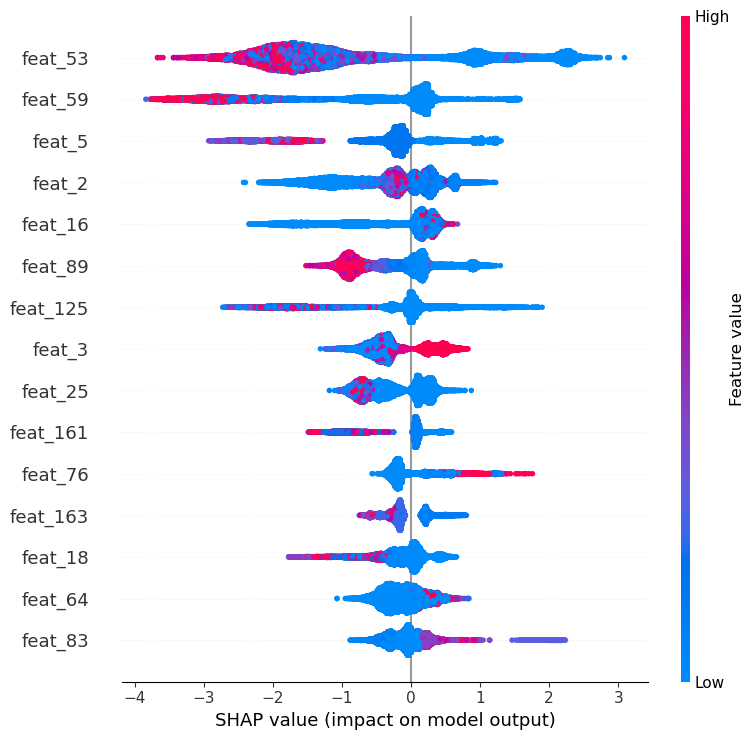

In [18]:
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_full)

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=feat_cols).sort_values(ascending=False)
shap_report = pd.DataFrame({
    "mean_abs_shap": mean_abs_shap,
    "shap_share": mean_abs_shap / mean_abs_shap.sum(),
    "drift_importance": drift_importance.reindex(mean_abs_shap.index),
})
print(shap_report.head(15).round(4))

shap.summary_plot(shap_values, X_full, max_display=15, show=True)

In [19]:
# The same report, sorted the other way: the most time-revealing features first,
# with where each one lands in the model's SHAP ranking (out of 76).
shap_report["shap_rank"] = np.arange(1, len(shap_report) + 1)
print(shap_report.sort_values("drift_importance", ascending=False).head(10)
      [["drift_importance", "shap_rank", "shap_share"]].round(4))

          drift_importance  shap_rank  shap_share
feat_103            0.3517         24      0.0131
feat_136            0.3355         16      0.0185
feat_2              0.0753          4      0.0465
feat_142            0.0354         32      0.0081
feat_112            0.0284         55      0.0022
feat_109            0.0259         37      0.0066
feat_3              0.0196          8      0.0363
feat_148            0.0099         42      0.0050
feat_144            0.0097         43      0.0049
feat_89             0.0049          6      0.0433


## Appendix: experiments that didn't beat the final model

Each idea below looked reasonable and was tested the same way: on the gap-matched split, validated on genuine labels only. None beat `data/submission.csv` on the leaderboard. They're kept with their results so the reasoning is on record.

Also tested earlier and removed from this notebook: a stricter 0.8 correlation threshold in `preprocessing.ipynb`, extra graph features, and averaging Random Forest with XGBoost. All three scored at or below the baseline on the gap-matched split.

### A1. Dropping the drift candidates from adversarial validation

Drop the features with high drift importance but below-median label relevance (the list printed in section 3), at the gap-matched split with `half_life=10`. Result: no improvement over keeping all 76.

In [20]:
# Does dropping these actually help, at the realistic gap? (half_life=10, the validated recency setting)
recency_weight_gap_hl10 = 0.5 ** ((GAP_TRAIN_CUTOFF - train_df_gap["time_step"]) / 10)
combined_weight_gap_hl10 = y_train_gap.map({0: 1.0, 1: scale_pos_weight_gap}) * recency_weight_gap_hl10

feat_cols_reduced = [c for c in feat_cols if c not in drop_candidates]
print(f"reduced feature count: {len(feat_cols_reduced)} (was {len(feat_cols)})")

xgb_gap_reduced = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    eval_metric="logloss", random_state=42, n_jobs=-1,
)
xgb_gap_reduced.fit(train_df_gap[feat_cols_reduced], y_train_gap, sample_weight=combined_weight_gap_hl10)
xgb_gap_reduced_proba = xgb_gap_reduced.predict_proba(val_df_gap[feat_cols_reduced])[:, 1]

print("gap-matched, half_life=10, all 76 features      PR-AUC: 0.8370  ROC-AUC: 0.8867  (from earlier sweep)")
print(f"gap-matched, half_life=10, {len(feat_cols_reduced)} features (drift dropped)  "
      f"PR-AUC: {average_precision_score(y_val_gap, xgb_gap_reduced_proba):.4f}  "
      f"ROC-AUC: {roc_auc_score(y_val_gap, xgb_gap_reduced_proba):.4f}")

reduced feature count: 70 (was 76)
gap-matched, half_life=10, all 76 features      PR-AUC: 0.8370  ROC-AUC: 0.8867  (from earlier sweep)
gap-matched, half_life=10, 70 features (drift dropped)  PR-AUC: 0.8360  ROC-AUC: 0.8617


### A2. Pseudo-labels from label propagation

`preprocessing.ipynb` fit `LabelPropagation` on all 31,235 genuine labels plus the 110,537 unlabeled rows, producing `label_propagated` and `label_propagated_confidence` for every row. Here, unlabeled rows with confidence ≥ 0.95 or ≥ 0.99 are added to the *training* set on top of the final recipe. Validation stays on genuine labels only.

**Outcome:** the adjacent-window check showed no gain at either threshold, and both pseudo-label submissions scored worse than `submission.csv` on the leaderboard. Ignore the large gap-matched gain below: it's leakage. Propagation used *all* genuine labels, including the `time_step` 21–35 rows this test withholds, so the pseudo-labels carry that withheld information back into training.

In [21]:
def pseudo_pool_at(threshold):
    pool = train_reduced[
        train_reduced["label"].isna() & (train_reduced["label_propagated_confidence"] >= threshold)
    ].copy()
    pool["label"] = pool["label_propagated"].astype(int)
    return pool


def fit_and_score(train_rows, val_rows, cutoff, label=""):
    X_tr, y_tr = train_rows[feat_cols], train_rows["label"]
    X_va, y_va = val_rows[feat_cols], val_rows["label"]

    spw = (y_tr == 0).sum() / (y_tr == 1).sum()
    recency = 0.5 ** ((cutoff - train_rows["time_step"]) / 10)
    weight = y_tr.map({0: 1.0, 1: spw}) * recency

    model = XGBClassifier(**BEST_PARAMS)
    model.fit(X_tr, y_tr, sample_weight=weight)
    proba = model.predict_proba(X_va)[:, 1]

    print(f"{label}: {len(train_rows)} train rows  "
          f"PR-AUC: {average_precision_score(y_va, proba):.4f}  ROC-AUC: {roc_auc_score(y_va, proba):.4f}")
    return model


print("--- Adjacent window (train <=30, validate on real 31-35) ---")
fit_and_score(train_df, val_df, SPLIT_POINT, "real only")
for threshold in [0.95, 0.99]:
    pool = pseudo_pool_at(threshold)
    extra = pool[pool["time_step"] <= SPLIT_POINT]
    fit_and_score(pd.concat([train_df, extra], ignore_index=True), val_df, SPLIT_POINT,
                  f"real + {len(extra)} pseudo (>= {threshold})")

# Gap-matched numbers are inflated: propagation used labels this test withholds
# (time_step 21-35), so the pseudo-labels leak them back in. Kept for reference only.
print("\n--- Gap-matched window (train <=20, validate on real 30-35) — LEAKY, see note ---")
fit_and_score(train_df_gap, val_df_gap, GAP_TRAIN_CUTOFF, "real only")
for threshold in [0.95, 0.99]:
    pool = pseudo_pool_at(threshold)
    extra = pool[pool["time_step"] <= GAP_TRAIN_CUTOFF]
    fit_and_score(pd.concat([train_df_gap, extra], ignore_index=True), val_df_gap, GAP_TRAIN_CUTOFF,
                  f"real + {len(extra)} pseudo (>= {threshold})")

--- Adjacent window (train <=30, validate on real 31-35) ---
real only: 26905 train rows  PR-AUC: 0.9883  ROC-AUC: 0.9976
real + 41513 pseudo (>= 0.95): 68418 train rows  PR-AUC: 0.9868  ROC-AUC: 0.9968
real + 32186 pseudo (>= 0.99): 59091 train rows  PR-AUC: 0.9882  ROC-AUC: 0.9974

--- Gap-matched window (train <=20, validate on real 30-35) — LEAKY, see note ---
real only: 18889 train rows  PR-AUC: 0.8391  ROC-AUC: 0.8960
real + 30445 pseudo (>= 0.95): 49334 train rows  PR-AUC: 0.9485  ROC-AUC: 0.9892
real + 23942 pseudo (>= 0.99): 42831 train rows  PR-AUC: 0.9441  ROC-AUC: 0.9892


#### Pseudo-label submissions

The final recipe trained on genuine labels plus pseudo-labels at each threshold, exported as `data/submission_xgb_pseudo095.csv` and `data/submission_xgb_pseudo099.csv`. Using propagated labels doesn't leak into `test.csv`, which was never part of propagation — but both scored worse than `submission.csv` on the leaderboard.

In [22]:
for threshold, filename in [(0.95, "submission_xgb_pseudo095.csv"), (0.99, "submission_xgb_pseudo099.csv")]:
    pool = pseudo_pool_at(threshold)
    full_with_pseudo = pd.concat([labeled, pool], ignore_index=True)
    X_full_pseudo, y_full_pseudo = full_with_pseudo[feat_cols], full_with_pseudo["label"]

    spw_pseudo = (y_full_pseudo == 0).sum() / (y_full_pseudo == 1).sum()
    recency_pseudo = 0.5 ** ((final_cutoff - full_with_pseudo["time_step"]) / FINAL_HALF_LIFE)
    weight_pseudo = y_full_pseudo.map({0: 1.0, 1: spw_pseudo}) * recency_pseudo

    model = XGBClassifier(**BEST_PARAMS)
    model.fit(X_full_pseudo, y_full_pseudo, sample_weight=weight_pseudo)
    proba = model.predict_proba(test_reduced[feat_cols])[:, 1]

    pd.DataFrame({"index": np.arange(len(test_reduced)), "target": proba}).to_csv(f"data/{filename}", index=False)

    print(f"threshold {threshold}: {len(labeled)} real + {len(pool)} pseudo "
          f"({(pool['label'] == 1).sum()} illicit) = {len(full_with_pseudo)} rows; "
          f"predicted illicit share on test {(proba >= 0.5).mean():.2%}; saved data/{filename}")

threshold 0.95: 31235 real + 48441 pseudo (5539 illicit) = 79676 rows; predicted illicit share on test 5.91%; saved data/submission_xgb_pseudo095.csv
threshold 0.99: 31235 real + 37282 pseudo (4421 illicit) = 68517 rows; predicted illicit share on test 5.45%; saved data/submission_xgb_pseudo099.csv


### A3. Feature removal guided by drift and SHAP

Two removal strategies, each at a few cut-offs, scored at the gap-matched split with the final recipe:

1. **Drop high-drift features**, the ones that most reveal the time period.
2. **Drop low-impact features**, the ones the model barely uses.

The SHAP ranking used for selection is recomputed from a model trained only on the gap-matched training rows (`time_step` ≤ 20). The SHAP in section 5 came from `final_model`, which saw every label including the 30–35 validation rows, so selecting with it would leak the validation answers into the choice of features.

In [23]:
gap_weight = y_train_gap.map({0: 1.0, 1: scale_pos_weight_gap}) * (
    0.5 ** ((GAP_TRAIN_CUTOFF - train_df_gap["time_step"]) / 10)
)


def score_cols(cols, label):
    model = XGBClassifier(**BEST_PARAMS)
    model.fit(train_df_gap[cols], y_train_gap, sample_weight=gap_weight)
    proba = model.predict_proba(val_df_gap[cols])[:, 1]
    print(f"{label:<38} {len(cols):>3} features  "
          f"PR-AUC: {average_precision_score(y_val_gap, proba):.4f}  ROC-AUC: {roc_auc_score(y_val_gap, proba):.4f}")
    return model


gap_model_all = score_cols(feat_cols, "all features (baseline)")

# SHAP ranking from the gap-trained model only, so selection never sees the 30-35 validation labels.
gap_shap = shap.TreeExplainer(gap_model_all).shap_values(train_df_gap[feat_cols])
gap_shap_rank = pd.Series(np.abs(gap_shap).mean(axis=0), index=feat_cols).sort_values(ascending=False)

print("\n-- drop high-drift features --")
for cutoff in [0.3, 0.05, 0.019]:
    drop = drift_importance[drift_importance >= cutoff].index.tolist()
    score_cols([c for c in feat_cols if c not in drop], f"drift >= {cutoff}")
    print(f"    dropped: {drop}")

print("\n-- drop low-impact features (keep top N by SHAP) --")
for n in [60, 50, 40, 30]:
    score_cols(list(gap_shap_rank.index[:n]), f"top {n} by SHAP")

print("\n-- both --")
high_drift = drift_importance[drift_importance >= 0.05].index
for n in [50, 40]:
    cols = [c for c in gap_shap_rank.index[:n] if c not in high_drift]
    score_cols(cols, f"top {n} by SHAP, minus drift >= 0.05")

all features (baseline)                 76 features  PR-AUC: 0.8391  ROC-AUC: 0.8960

-- drop high-drift features --
drift >= 0.3                            74 features  PR-AUC: 0.8312  ROC-AUC: 0.8748
    dropped: ['feat_103', 'feat_136']
drift >= 0.05                           73 features  PR-AUC: 0.8488  ROC-AUC: 0.9056
    dropped: ['feat_2', 'feat_103', 'feat_136']
drift >= 0.019                          69 features  PR-AUC: 0.8512  ROC-AUC: 0.9083
    dropped: ['feat_2', 'feat_3', 'feat_103', 'feat_109', 'feat_112', 'feat_136', 'feat_142']

-- drop low-impact features (keep top N by SHAP) --
top 60 by SHAP                          60 features  PR-AUC: 0.8283  ROC-AUC: 0.8692
top 50 by SHAP                          50 features  PR-AUC: 0.8316  ROC-AUC: 0.8833
top 40 by SHAP                          40 features  PR-AUC: 0.8308  ROC-AUC: 0.8864
top 30 by SHAP                          30 features  PR-AUC: 0.8246  ROC-AUC: 0.8770

-- both --
top 50 by SHAP, minus drift >= 0.05     47 

**Result on validation:** dropping high-drift features helped and dropping low-impact features hurt. Removing only `feat_103`/`feat_136` made things worse, since the model barely used them; the gain came once `feat_2` went too. The 0.019 cut-off (7 features dropped) scored best (0.8512 vs. 0.8391), and the 0.05 cut-off (3 dropped) got most of the gain.

**Outcome on the leaderboard:** worse than `submission.csv`. A ~0.01 gain on a single validation window, picked as the best of three cut-offs, is within what chance can produce. And a feature that drifts within `time_step` 1–35 can still be useful for 36–49. Both versions are exported below.

In [24]:
for cutoff, filename in [(0.019, "submission_xgb_dropdrift0019.csv"), (0.05, "submission_xgb_dropdrift005.csv")]:
    cols = [c for c in feat_cols if drift_importance[c] < cutoff]

    model = XGBClassifier(**BEST_PARAMS)
    model.fit(labeled[cols], y_full, sample_weight=combined_weight_full)
    proba = model.predict_proba(test_reduced[cols])[:, 1]

    pd.DataFrame({"index": np.arange(len(test_reduced)), "target": proba}).to_csv(f"data/{filename}", index=False)
    print(f"drift < {cutoff}: {len(cols)} features; predicted illicit share on test {(proba >= 0.5).mean():.2%}; "
          f"saved data/{filename}")

drift < 0.019: 69 features; predicted illicit share on test 6.61%; saved data/submission_xgb_dropdrift0019.csv
drift < 0.05: 73 features; predicted illicit share on test 5.34%; saved data/submission_xgb_dropdrift005.csv


### A4. Slower recency decay (`half_life=20`)

The final recipe with `half_life=20`: the oldest labeled row keeps `0.5 ** (34/20) ≈ 30%` of its weight, vs. ≈9% at `half_life=10`. Exported as `data/submission_xgb_recency_hl20.csv`. The gap-matched sweep in section 3 ranked `half_life=20` below 10, and an earlier version (before hyperparameter tuning) scored below `half_life=10` on the leaderboard.

In [25]:
HALF_LIFE_20 = 20
recency_weight_hl20 = 0.5 ** ((final_cutoff - labeled["time_step"]) / HALF_LIFE_20)
combined_weight_hl20 = y_full.map(class_weight_map_full) * recency_weight_hl20

final_model_hl20 = XGBClassifier(**BEST_PARAMS)
final_model_hl20.fit(X_full, y_full, sample_weight=combined_weight_hl20)

test_proba_hl20 = final_model_hl20.predict_proba(test_reduced[feat_cols])[:, 1]

submission_xgb_hl20 = pd.DataFrame({
    "index": np.arange(len(test_reduced)),
    "target": test_proba_hl20,
})
submission_xgb_hl20.to_csv("data/submission_xgb_recency_hl20.csv", index=False)

print("predicted illicit share on test (half_life=20):", (test_proba_hl20 >= 0.5).mean())
print("saved data/submission_xgb_recency_hl20.csv:", submission_xgb_hl20.shape)
submission_xgb_hl20.head()

predicted illicit share on test (half_life=20): 0.04403418357361863
saved data/submission_xgb_recency_hl20.csv: (15329, 2)


,index,target
0,0,0.001065
1,1,0.013230
2,2,0.002278
3,3,0.001853
4,4,0.000068


### A5. Random Forest submission

Random Forest trained on all labeled data, exported as `data/submission_rf.csv` for comparison. It was consistently weaker than XGBoost on validation (section 2).

In [26]:
final_rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
final_rf.fit(X_full, y_full)
rf_test_proba = final_rf.predict_proba(test_reduced[feat_cols])[:, 1]

submission_rf = pd.DataFrame({
    "index": np.arange(len(test_reduced)),
    "target": rf_test_proba,
})
submission_rf.to_csv("data/submission_rf.csv", index=False)

print("predicted illicit share on test (Random Forest):", (rf_test_proba >= 0.5).mean())
print("saved data/submission_rf.csv:", submission_rf.shape)

predicted illicit share on test (Random Forest): 0.03157414051797247
saved data/submission_rf.csv: (15329, 2)
